# Экзаменационная задача №15. Оценка стоимости опциона на масштабирование ИТ-платформы

**Дисциплина:** Экономика информатизации, лекция №16
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №15: ОЦЕНКА СТОИМОСТИ ОПЦИОНА НА МАСШТАБИРОВАНИЕ ИТ-ПЛАТФОРМЫ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №16)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Госпортал можно расширить через 2 года за 80 млн руб. Решать сейчас не обязательно: через 2 года станет ясно,
нужно ли расширение. Право, но не обязанность вложить деньги в будущем, это **реальный опцион колл** на расширение.
Обычный NPV считает, что решение принимается «сейчас или никогда», такую гибкость не видит и занижает ценность проекта.

**Цель:** оценить опцион на расширение по формуле Блэка–Шоулза, сравнить с NPV без опциона и построить дерево решений.

Тема лекции №16: реальные опционы (расширение, отсрочка, отказ), формула Блэка–Шоулза, биномиальная модель,
ценность гибкости при неопределённости.

## 2. Исходные данные

In [2]:
S = 150.0       # текущая стоимость платформы (PV денежных потоков от масштабирования), млн руб.
K = 80.0        # инвестиции в масштабирование через 2 года (цена исполнения), млн руб.
sigma = 0.25    # волатильность стоимости, в год
rf = 0.06       # безрисковая ставка (непрерывное начисление)
T = 2.0         # срок до решения, лет
pd.DataFrame({"Параметр": ["S — стоимость базового актива", "K — инвестиции (страйк)", "σ — волатильность", "r — безрисковая ставка", "T — срок"],
              "Значение": ["150 млн руб.", "80 млн руб.", "25% в год", "6%", "2 года"], "Аналог в финансовом опционе": ["цена акции", "цена исполнения", "волатильность акции", "безрисковая ставка", "срок до экспирации"]})

,Параметр,Значение,Аналог в финансовом опционе
0,S — стоимость базового актива,150 млн руб.,цена акции
1,K — инвестиции (страйк),80 млн руб.,цена исполнения
2,σ — волатильность,25% в год,волатильность акции
3,r — безрисковая ставка,6%,безрисковая ставка
4,T — срок,2 года,срок до экспирации


**Допущения:** «текущая стоимость платформы» это приведённая стоимость денег, которые даст расширение
(базовый актив опциона). 80 млн руб. платим только если решим расширяться. Опцион европейский (решение ровно через 2 года).
Стоимость актива меняется по логнормальному закону.

## 3. Математическая модель

**Блэк–Шоулз:**
$$C = S\,N(d_1) - K e^{-rT} N(d_2),\qquad d_1 = \frac{\ln(S/K) + (r + \sigma^2/2)T}{\sigma\sqrt T},\qquad d_2 = d_1 - \sigma\sqrt T$$

**NPV без опциона** (обязаны вложить через 2 года при любом исходе): $NPV_{стат} = S - K e^{-rT}$.
Ценность гибкости: $C - NPV_{стат} \ge 0$. Для сравнения расширение «сейчас»: $S-K$.

**Биномиальное дерево (Кокс–Росс–Рубинштейн):** $u = e^{\sigma\sqrt{\Delta t}}$, $d = 1/u$,
$q = \dfrac{e^{r\Delta t} - d}{u - d}$. В конечных узлах $C = \max(S_T - K, 0)$, назад по дереву $C = e^{-r\Delta t}[qC_u + (1-q)C_d]$.

## 4. Реализация расчёта
### 4.1. Формула Блэка–Шоулза

In [3]:
from scipy.stats import norm
def black_scholes(S=S, K=K, sigma=sigma, r=rf, T=T):
    d1 = (math.log(S / K) + (r + sigma**2 / 2) * T) / (sigma * math.sqrt(T))
    d2 = d1 - sigma * math.sqrt(T)
    return S * norm.cdf(d1) - K * math.exp(-r * T) * norm.cdf(d2), d1, d2

C, d1, d2 = black_scholes()
PV_K = K * math.exp(-rf * T)
npv_static = S - PV_K
npv_now = S - K
print(f"d1 = {d1:.4f}, d2 = {d2:.4f};  N(d1) = {norm.cdf(d1):.4f}, N(d2) = {norm.cdf(d2):.4f}")
print(f"PV(K) = 80·e^(−0.06·2) = {PV_K:.2f} млн руб.")
print(f"Стоимость опциона (Блэк–Шоулз):             C = {C:.2f} млн руб.")
print(f"NPV без опциона (обязательство через 2 года): {npv_static:.2f} млн руб.")
print(f"NPV масштабирования сейчас (S − K):          {npv_now:.2f} млн руб.")
print(f"Ценность гибкости C − NPV_стат = {C - npv_static:.2f} млн руб. ({(C-npv_static)/npv_static:.1%})")
print(f"Вероятность исполнения в риск-нейтральном мире N(d2) = {norm.cdf(d2):.1%}")

d1 = 2.2942, d2 = 1.9406;  N(d1) = 0.9891, N(d2) = 0.9738
PV(K) = 80·e^(−0.06·2) = 70.95 млн руб.
Стоимость опциона (Блэк–Шоулз):             C = 79.27 млн руб.
NPV без опциона (обязательство через 2 года): 79.05 млн руб.
NPV масштабирования сейчас (S − K):          70.00 млн руб.
Ценность гибкости C − NPV_стат = 0.22 млн руб. (0.3%)
Вероятность исполнения в риск-нейтральном мире N(d2) = 97.4%


### 4.2. Биномиальное дерево решений

In [4]:
def binomial(steps=2, S=S, K=K, sigma=sigma, r=rf, T=T):
    dt = T / steps; u = math.exp(sigma * math.sqrt(dt)); d = 1 / u
    q = (math.exp(r * dt) - d) / (u - d); disc = math.exp(-r * dt)
    St = [[S * u**j * d**(i - j) for j in range(i + 1)] for i in range(steps + 1)]
    V = [[0.0] * (i + 1) for i in range(steps + 1)]
    V[steps] = [max(s - K, 0) for s in St[steps]]
    for i in range(steps - 1, -1, -1):
        V[i] = [disc * (q * V[i + 1][j + 1] + (1 - q) * V[i + 1][j]) for j in range(i + 1)]
    return St, V, u, d, q

St, Vt, u, d, q = binomial(2)
print(f"u = {u:.4f}, d = {d:.4f}, q = {q:.4f}")
tree = pd.DataFrame([{"Год": i, "Узел": ["↓↓", "↑↓", "↑↑"][j] if i == 2 else (["↓", "↑"][j] if i == 1 else "старт"),
                      "Стоимость платформы": St[i][j], "Ценность опциона": Vt[i][j],
                      "Решение": ("масштабировать" if St[i][j] > K else "не масштабировать") if i == 2 else "ждать"}
                     for i in range(3) for j in range(i + 1)])
display(tree.round(2))
conv = pd.DataFrame({"Шагов": [2, 10, 50, 200, 1000], "Цена опциона": [binomial(n)[1][0][0] for n in [2, 10, 50, 200, 1000]]})
conv["Отклонение от Б–Ш"] = conv["Цена опциона"] - C
conv.round(3)

u = 1.2840, d = 0.7788, q = 0.5602


,Год,Узел,Стоимость платформы,Ценность опциона,Решение
0,0,старт,150.00,79.05,ждать
1,1,↓,116.82,41.48,ждать
2,1,↑,192.60,117.26,ждать
3,2,↓↓,90.98,10.98,масштабировать
4,2,↑↓,150.00,70.00,масштабировать
5,2,↑↑,247.31,167.31,масштабировать


,Шагов,Цена опциона,Отклонение от Б–Ш
0,2,79.05,-0.22
1,10,79.26,-0.01
2,50,79.27,-0.00
3,200,79.27,0.00
4,1000,79.27,-0.00


### 4.3. Чувствительность: когда гибкость ценна

In [5]:
rows = []
for s_ in [60, 80, 100, 150, 200]:
    c_ = black_scholes(S=s_)[0]; st_ = s_ - PV_K
    rows.append({"S, млн": s_, "Опцион C": c_, "NPV стат.": st_, "Ценность гибкости": c_ - max(st_, 0) if st_ > 0 else c_,
                 "Решение по NPV": "инвестировать" if st_ > 0 else "отказаться"})
sens_S = pd.DataFrame(rows)
sens_sig = pd.DataFrame({"σ": [0.10, 0.25, 0.40, 0.60], "Опцион C": [black_scholes(sigma=s)[0] for s in [0.10, 0.25, 0.40, 0.60]]})
sens_sig["Ценность гибкости"] = sens_sig["Опцион C"] - npv_static
display(sens_S.round(2)); sens_sig.round(2)

,"S, млн",Опцион C,NPV стат.,Ценность гибкости,Решение по NPV
0,60,4.71,-10.95,4.71,отказаться
1,80,15.71,9.05,6.66,инвестировать
2,100,31.64,29.05,2.60,инвестировать
3,150,79.27,79.05,0.22,инвестировать
4,200,129.07,129.05,0.02,инвестировать


,σ,Опцион C,Ценность гибкости
0,0.10,79.05,0.00
1,0.25,79.27,0.22
2,0.40,81.50,2.46
3,0.60,87.65,8.60


## 5. Визуализация результатов

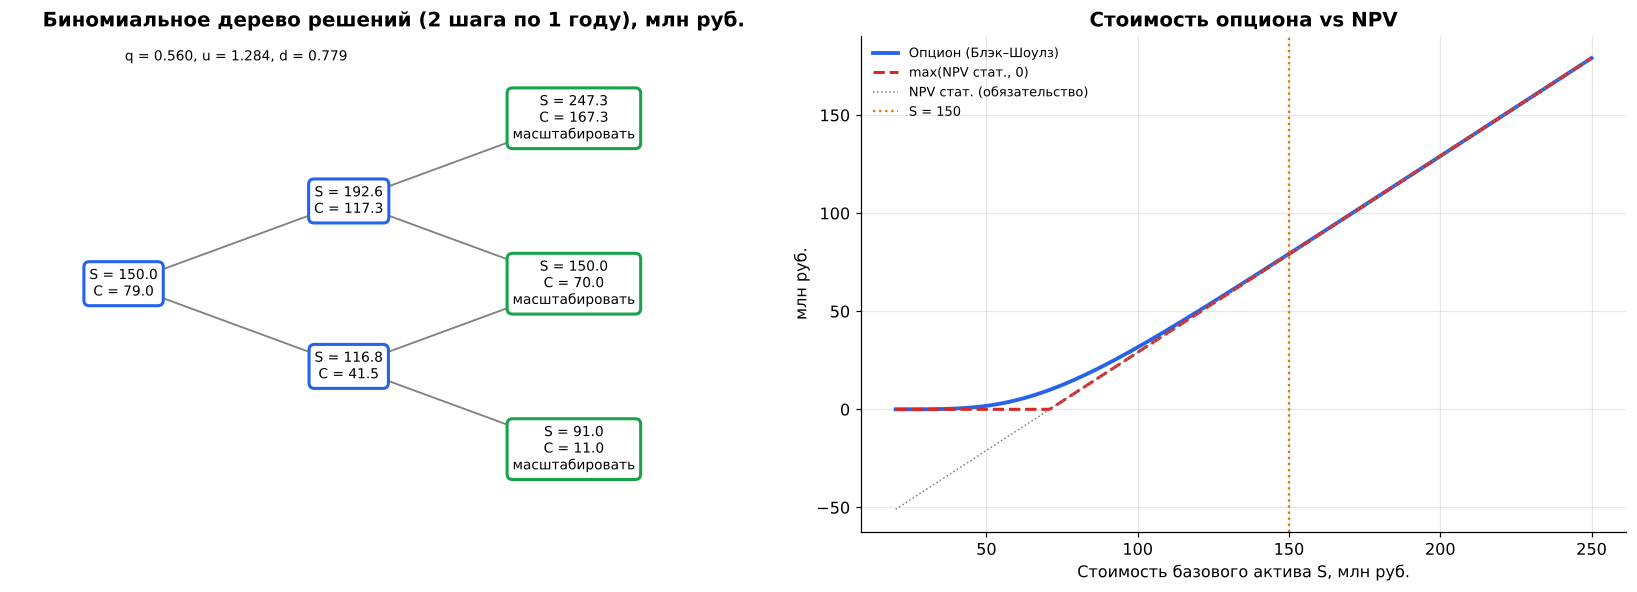

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
ax = axes[0]; ax.axis("off"); ax.set_xlim(-0.5, 2.9); ax.set_ylim(-1.5, 1.5)
pos = {(i, j): (i, (j - i / 2) * 1.0) for i in range(3) for j in range(i + 1)}
for i in range(2):
    for j in range(i + 1):
        for k in (j, j + 1):
            ax.plot([pos[(i, j)][0], pos[(i + 1, k)][0]], [pos[(i, j)][1], pos[(i + 1, k)][1]], color="gray", lw=1.2)
for (i, j), (x, y) in pos.items():
    exercise = i == 2 and St[i][j] > K
    col = PALETTE[2] if exercise else (PALETTE[1] if i == 2 else PALETTE[0])
    label = f"S = {St[i][j]:.1f}\nC = {Vt[i][j]:.1f}" + ("\nмасштабировать" if exercise else ("\nотказ" if i == 2 else ""))
    ax.text(x, y, label, ha="center", va="center", fontsize=9, bbox=dict(boxstyle="round,pad=0.4", fc="white", ec=col, lw=2))
ax.text(0.5, 1.35, f"q = {q:.3f}, u = {u:.3f}, d = {d:.3f}", ha="center", fontsize=9)
ax.set_title("Биномиальное дерево решений (2 шага по 1 году), млн руб.")
ax = axes[1]
Ss = np.linspace(20, 250, 200)
ax.plot(Ss, [black_scholes(S=s)[0] for s in Ss], lw=2.5, label="Опцион (Блэк–Шоулз)")
ax.plot(Ss, np.maximum(Ss - PV_K, 0), lw=2, ls="--", label="max(NPV стат., 0)")
ax.plot(Ss, Ss - PV_K, lw=1, ls=":", color="gray", label="NPV стат. (обязательство)")
ax.axvline(S, color=PALETTE[3], ls=":", label="S = 150")
ax.set_xlabel("Стоимость базового актива S, млн руб."); ax.set_ylabel("млн руб."); ax.set_title("Стоимость опциона vs NPV")
ax.legend(fontsize=8.5)
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Опцион стоит около 79,3 млн руб.** NPV без опциона (обязаны вложить через 2 года) около 79,05 млн руб.,
  расширение «сейчас» 70 млн руб.
- **Гибкость почти ничего не стоит (около 0,2 млн руб., 0,3 %).** Это не ошибка расчёта, а особенность исходных данных:
  опцион глубоко «в деньгах» ($S/K\approx1{,}9$). Шанс, что через 2 года стоимость упадёт ниже 80 млн руб., всего около 3 %
  ($N(d_2)\approx0{,}97$). Правом отказаться почти никогда не воспользуются, поэтому опцион почти равен обязательству.
- Опцион дороже расширения «сейчас» (79,3 против 70 млн руб.) в основном потому, что платёж 80 млн руб. **откладывается
  на 2 года** (экономия на процентах около 9 млн руб.), а не из-за права отказаться.
- **Биномиальное дерево** с 2 шагами даёт почти то же (около 79,05 млн руб.) и сходится к Блэку–Шоулзу уже при 10–50 шагах.
  Расширяться выгодно во всех трёх конечных состояниях: даже в худшем стоимость около 91 млн руб., это больше 80.
  Поэтому дерево из 2 шагов совпадает с обычным NPV.
- **Когда гибкость действительно ценна:** когда $S$ близка к $K$ (60–100 млн руб.) и волатильность высокая. Тогда опцион
  стоит в разы больше обычного NPV, а при $S < PV(K)$ обычный NPV отверг бы проект, хотя опцион чего-то стоит.

## 7. Выводы и рекомендации

1. Ценность проекта с опционом около **79,3 млн руб.**, обычный NPV около 79,05 млн руб. Оба метода говорят одно:
   **расширение выгодно**.
2. При этих цифрах опционный анализ почти ничего не добавляет к NPV: неопределённость маленькая по сравнению с запасом
   стоимости. Его стоит применять, когда $S$ близка к $K$ или волатильность высокая.
3. На практике: зарезервировать деньги на расширение через 2 года, но оставить контрольную точку. Если портал будут
   использовать меньше плана, пересчитать решение.
4. Ограничения модели: актив не продаётся на бирже (σ оценена субъективно), расширяться можно и раньше (американский опцион),
   а вложения могут подорожать. Это стоит учесть в расширенной модели.